# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/data00077/flyrank-ml-internship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [10]:
import json, subprocess, sys, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

REPO = Path("/content/flyrank-ml-internship")
if not REPO.exists():
    subprocess.run(["git", "clone", "https://github.com/data00077/flyrank-ml-internship.git", str(REPO)], check=True)

# Pipeline steps 1-4 (step 5 is only a PDF and is not needed for the paper)
for script in ["01_prepare_features.py", "02_baseline_score.py",
               "03_train_model.py", "04_evaluate_and_export.py"]:
    r = subprocess.run([sys.executable, f"scripts/{script}"], cwd=REPO,
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise SystemExit(f"{script} failed")
ASSETS = REPO / "docs/assets"
ASSETS.mkdir(parents=True, exist_ok=True)
print("setup done")


setup done


## 1. Question

*The research question and the decision it supports.*


**Question:** Can observable page signals (age, freshness, visibility, search position, content type) rank content pages that are observed to be declining better than a transparent weighted baseline score?

**Decision it supports:** A content team uses the ranking to decide which pages to review for refresh first.

**Why a model:** a hand-written score fixes its weights in advance; a model can learn how many signals combine and be tested on clients it has never seen.

In [11]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


print("Seed:", SEED)

Seed: 42


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

**Release:** the anonymized FlyRank ML Internship starter slice (`content_refresh_anonymized.csv`), 30,000 content items, 44 columns, one row per pseudonymized content item.

**Window:** the slice reports 90-day metrics plus last-30 and previous-30-day comparisons; it has no calendar date column, so the split is by client, not by date.

 **Excluded / not used as features:** hashed `content_id` and `client_id` (grouping only, never features); trend fields (`trend_direction`, `trend_pct`), because the label is derived from them; last-30 and previous-30-day comparison columns, excluded to avoid indirect leakage into the label.

**Public-safety:** client names, domains, URLs, titles and queries were removed before release. This paper shows aggregates and charts only.

In [12]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

df = pd.read_csv(REPO / "data/raw/content_refresh_anonymized.csv")
meta = json.load(open(REPO / "data/processed/feature_metadata.json"))

print("raw rows:", meta["initial_rows"], "| prepared rows:", meta["prepared_rows"])
print("duplicate content_id dropped:", meta["initial_rows"] - meta["prepared_rows"])
print("clients:", df["client_id"].nunique())
print("declining rows:", meta["declining_rows"], "| rate:", round(meta["declining_rate"], 3))
print("\nTop missing-value rates:")
print(df.isna().mean().sort_values(ascending=False).head(8).round(3))

raw rows: 30000 | prepared rows: 30000
duplicate content_id dropped: 0
clients: 32
declining rows: 16262 | rate: 0.542

Top missing-value rates:
provider_used        0.715
word_count           0.257
char_count           0.257
word_count_tier      0.257
char_count_tier      0.257
model_used           0.191
trend_pct            0.113
competition_level    0.087
dtype: float64


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*


**Assumptions:** a page whose observed 90-day trend direction is "down" is declining; the starter slice is representative enough for a first, directional analysis.

**Label:** `is_declining_label = (trend_direction == 'down')`. 54.2% of rows are positive.

**Features:** 18 numeric (visibility, clicks, sessions, age, days since update, CTR, average position, engagement, scroll, AI traffic share; counts log-transformed) and 8 categorical (competition level, content type, intent, age tier, freshness tier, word-count tier, impression tier, position tier).

**Baseline:** a transparent weighted score: 40% visibility (percentile of log 90-day impressions), 30% freshness risk (percentile of days since last update), 25% position opportunity (closeness to the top positions, weighted by visibility), 5% depth gap (thin content weighted by visibility). Pages are ranked highest score first. The score does not use the label or any trend field.

**Validation design:** client-holdout split (the model is tested on clients it did not train on), seed 42. Three models compared: logistic regression, decision tree, random forest.

**Leakage checks:** trend fields (`trend_direction`, `trend_pct`) are excluded because the label is derived from them; last-30 and previous-30-day comparison columns are excluded to avoid indirect leakage; hashed IDs are used for grouping only. A code check confirms no label-related column is among the 26 model features.

In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

features = meta["model_numeric_features"] + meta["model_categorical_features"]
label_related = ["trend_direction", "trend_pct",
                 "impressions_last_30d", "clicks_last_30d", "sessions_last_30d",
                 "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d",
                 "content_id", "client_id"]
leaks = [c for c in label_related if c in features]
assert not leaks, f"leakage: {leaks}"
print("features:", len(features), "| label-related columns used as features:", leaks)


features: 26 | label-related columns used as features: []


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*


**Setup.** All methods are scored on the same held-out clients: 27,675 training pages and 2,325 test pages (client-holdout split, seed 42). The baseline is the weighted score from Section 3. Because the use is a review queue, the main metric is **precision at top k**: the share of the k highest-ranked pages that are observed to be declining. ROC AUC is shown as a whole-ranking check. About 39% of test pages are observed declining (54% across all pages), so a random pick of k pages would score about 0.39.

| Method | ROC AUC | Avg. precision | P@20 | P@50 | P@100 | Recall |
|---|---|---|---|---|---|---|
| Baseline score | 0.627 | 0.468 | 0.15 | 0.24 | 0.36 | 0.189 |
| Logistic regression | 0.700 | 0.522 | 0.35 | 0.40 | 0.44 | 0.567 |
| Decision tree | 0.742 | 0.575 | 0.45 | 0.58 | 0.62 | 0.716 |
| **Random forest** | **0.750** | **0.618** | **0.65** | **0.74** | **0.72** | **0.744** |

**Reading the table.** The random forest ranks best on every ranking metric (AUC 0.750 vs 0.627; P@50 0.74 vs 0.24). The baseline's top-ranked pages were observed declining less often than a random pick (0.24 and 0.36 vs about 0.39), so in this slice its ordering was not useful for finding declining pages. Logistic regression separates pages better than the baseline overall (AUC 0.700) but its top 50 is only near random level (0.40). These are directional results: the forest was chosen by P@50 on this same test split, and P@50 rests on only 50 pages (roughly ±0.06 sampling noise).

train rows: 27675 | test rows: 2325 | split: client_holdout
test pages: 2325 | test clients: 6 | test declining rate: 0.391


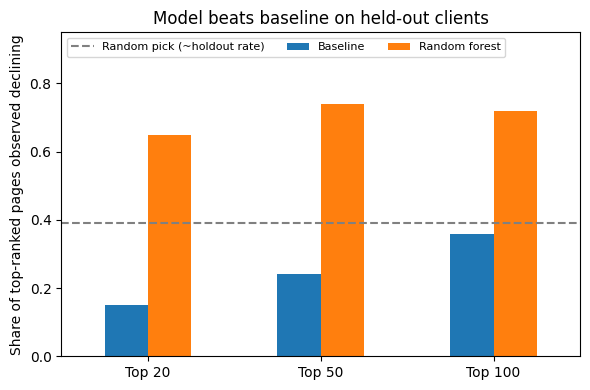

,roc_auc,average_precision,precision_at_20,precision_at_50,precision_at_100,recall,accuracy
Baseline score,0.627,0.468,0.15,0.24,0.36,0.189,0.609
Decision Tree,0.742,0.575,0.45,0.58,0.62,0.716,0.677
Logistic Regression,0.700,0.522,0.35,0.40,0.44,0.567,0.661
Random Forest,0.750,0.618,0.65,0.74,0.72,0.744,0.672


In [14]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

res = json.load(open(REPO / "outputs/model_results.json"))
base = {k.replace("baseline_", ""): v for k, v in res["baseline"].items()}
rows = {"Baseline score": base, **{n.replace("_", " ").title(): m for n, m in res["models"].items()}}
cols = ["roc_auc", "average_precision", "precision_at_20", "precision_at_50",
        "precision_at_100", "recall", "accuracy"]
table = pd.DataFrame(rows).T.reindex(columns=cols).round(3)



preds = pd.read_csv(REPO / "data/processed/model_predictions.csv")
test = preds[preds["split"] == "test"]
holdout_rate = test["is_declining_label"].mean()
print("train rows:", res["train_rows"], "| test rows:", res["test_rows"],
      "| split:", res["split_strategy"])
print("test pages:", len(test), "| test clients:", test["client_id"].nunique(),
      "| test declining rate:", round(holdout_rate, 3))

ks = ["precision_at_20", "precision_at_50", "precision_at_100"]
ax = pd.DataFrame({"Baseline": [base[k] for k in ks],
                   "Random forest": [res["models"]["random_forest"][k] for k in ks]},
                  index=["Top 20", "Top 50", "Top 100"]).plot.bar(figsize=(6, 4), rot=0)
ax.axhline(holdout_rate, linestyle="--", color="gray", label="Random pick (~holdout rate)")
ax.set_ylabel("Share of top-ranked pages observed declining")
ax.set_title("Model beats baseline on held-out clients")
ax.set_ylim(0, 0.95)
ax.legend(loc="upper left", ncol=3, fontsize=8)
plt.tight_layout()
plt.savefig(ASSETS / "model_vs_baseline.png", dpi=200)
plt.show()
table

## 5. Limitations

*What this work cannot claim.*

- **Observed, not causal.** The label is an observed downward trend; this work does not show that refreshing a page causes recovery.
- **Model chosen on the reporting split.** The best model was picked by precision@50 on the same held-out clients used to report results, so its score is somewhat optimistic.
- **Small top-k.** Precision@50 rests on 50 pages (roughly ±0.06 noise); precision@100 is steadier but still small.

**Small, anonymized slice.** 30,000 pages from 32 clients; the test split is 2,325 pages from only 6 clients. Results are directional, not production evidence.

- **Client effects.** The test clients have a lower declining rate (about 39%) than the full data (54%). Errors may cluster by client, and new clients may behave differently.
- **Feature importance is association.** Importances come from a model refit on all 30,000 rows; they show which signals the model used, not why pages decline, and their direction was not tested.
- **The refresh queue is illustrative.** Queue scores for all 30,000 pages come from models refit on all rows, so scores for training clients are in-sample. The queue shows the workflow; it is not a performance estimate.
- **Reason codes are descriptive.** Some codes (for example `declining_with_demand`) are derived from the observed label and are not model findings.
- **Label definition.** "Declining" depends on how trend direction was computed upstream.
- **No calendar dates** in the slice, so time-based validation was not possible.

In [15]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


print("limitations reviewed")

limitations reviewed


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

Ordered by how well the evidence supports them. All are decision-support, not causal claims.

1. **Order the first review batch with the model ranking, not the baseline score.**
   *Evidence:* on held-out clients the random forest's top 50 was 74% observed-declining vs 24% for the baseline and about 39% for a random pick (Section 4).
   *Confidence:* medium. The model was selected on the same split and the top-50 sample is small.
2. **Retire the baseline score as an ordering rule.**
   *Evidence:* its top 20/50/100 were observed declining less often than a random pick (0.15 / 0.24 / 0.36 vs about 0.39); ROC AUC 0.627.
   *Confidence:* medium.
3. **Look first at visible pages: those with many days showing impressions and high 90-day impressions.**
   *Evidence:* `days_with_impressions` and `log_impressions_90d` are the two strongest model signals.
   *Confidence:* medium-low. Importance shows what the model used, not direction or cause.
4. **Check pages with weaker search position and older content next.**
   *Evidence:* `avg_position` and `content_age_days` are the next strongest signals.
   *Confidence:* low. Direction was not tested; inspect a sample before acting.
5. **Re-test on new clients and a later time window before using the ranking operationally.**
   *Evidence:* 32 clients, one slice, no dates, model chosen on the reporting split (Section 5).
   *Confidence:* high that this check is needed.

In [16]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

queue = pd.read_csv(REPO / "outputs/refresh_queue.csv")
print(queue.shape)
print(queue["confidence"].value_counts())
print(queue["suggested_action"].value_counts())
print(queue["final_reason_codes"].str.split("|").explode().value_counts().head(10))

(30000, 28)
confidence
low       15000
medium    11398
high       3602
Name: count, dtype: int64
suggested_action
monitor                          13083
refresh                           8188
refresh_and_review_ctr            6654
refresh_and_review_engagement     1993
expand_and_refresh                  82
Name: count, dtype: int64
final_reason_codes
declining_with_demand          13152
visible_model_opportunity      10650
low_ctr_visible_page            9759
ctr_review_candidate            9759
general_refresh_review          9117
model_decline_risk              8427
page_one_decay_risk             7076
low_engagement_visible_page     6508
engagement_review_candidate     6508
thin_visible_page                 82
Name: count, dtype: int64


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

In [17]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

for f in (REPO / "outputs/charts").glob("*.svg"):
    shutil.copy(f, ASSETS / f.name)
print(sorted(p.name for p in ASSETS.iterdir()))

['action_mix.svg', 'confidence_mix.svg', 'model_vs_baseline.png', 'top_feature_importance.svg', 'top_reason_codes.svg', 'trend_distribution.svg']


In [18]:
shutil.make_archive("/content/paper_assets", "zip", ASSETS)
from google.colab import files
files.download("/content/paper_assets.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Demo outline (5 minutes)

**0:00–0:45 · The problem.** FlyRank tracks how published content performs in search for its clients. Pages age and some start losing traffic, but a team can't review every page. Which ones should it look at first?

**0:45–1:45 · The data and the question.** An anonymized slice of 30,000 content pages from 32 clients, with 90-day search and engagement metrics. Question: can observable signals (age, freshness, visibility, position, content type) rank pages that are observed to be declining better than a transparent weighted score?

**1:45–3:00 · The method.** Label: pages whose observed 90-day trend is down (54% of pages). Baseline: a weighted visibility, freshness and position score. Three models (logistic regression, decision tree, random forest). The test is on clients the models never saw: 2,325 pages from 6 held-out clients, with trend fields excluded to avoid leakage. The measure is precision at top k, because the real use is a review queue.

**3:00–3:45 · One chart.** Show `model_vs_baseline.png`: share of the top 20, 50 and 100 pages that are observed declining, with the dashed random-pick line at about 39%.

**3:45–4:30 · One honest result.** The random forest's top 50 were 74% observed declining against 24% for the baseline. The baseline did worse than a random pick. Caveats: the model was selected on the same split, the top-50 sample is small, and there were only 6 test clients, so this is directional.

**4:30–5:00 · One recommendation.** Use the model ranking, not the baseline score, to order the first review batch, then re-test on new clients and a later time window before relying on it. This is decision support, not proof that refreshing a page helps.

## Cell 2: Two shareable cuts (directly under the outline)

```
## Shareable cuts

### Social post (methodology)

How do you know a ranking model is actually better than a simple rule?

For my FlyRank ML internship capstone I tried to rank content pages that are losing search traffic, so a team knows which to review first. The part I'm happiest with is the method, not the model:

• Tested on clients the model never saw, so it can't memorize client-specific patterns.
• Compared against a transparent baseline score, and against a plain random pick (about 39% of test pages were declining).
• Judged by precision at the top of the list, because the real use is a review queue.

Result: the random forest's top 50 were 74% observed declining. The baseline's were 24%, worse than random. The honest caveats: I picked the model on the same split and the test set had only 6 clients, so it's directional, not proof.

Lesson: always compute the "random pick" number before celebrating a metric.

Paper and reproducible notebook: <PAPER_URL>

#MachineLearning #DataScience #SEO

### Employer summary (3 sentences)

I built a ranking system on an anonymized slice of FlyRank's content-performance data (30,000 pages from 32 clients) to help decide which declining pages to review first, using Python and scikit-learn with a client-holdout validation design and leakage checks. On clients it had not seen, a random forest placed 74% observed-declining pages in its top 50, versus 24% for a transparent baseline and about 39% for a random pick. I reported it as directional decision support, noting that the model was selected on the same split and the test set had only 6 clients, and published a paper and reproducible notebook: <PAPER_URL>
```

---



## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.